# Optical Flow

## Introduction
In this notebook, we will explore the concept of optical flow using OpenCV. Optical flow is a technique used to estimate the motion of objects between two consecutive frames in a video sequence. By analyzing the changes in intensity patterns, we can infer the motion of pixels and visualize it in a meaningful way.

## Learning Objectives

- Understand the basics of optical flow.
- Implement optical flow using the Farneback method in OpenCV.
- Visualize the motion of objects in a video.

## Instructions

Please follow these steps to complete the lab:

1. **Import necessary libraries**: We'll start by importing NumPy and OpenCV.
2. **Capture video**: Use OpenCV to read a video file.
3. **Initialize variables**: Prepare variables for processing the frames.
4. **Calculate optical flow**: Use the Farneback method to compute the flow between frames.
5. **Visualize the results**: Convert the flow data to a visual format and display it.
6. **Handle key events**: Allow saving the frames and exiting the display.
7. **Step 7: Create a report**

You are asked to write a short (no more than 2 pages) report of your work, answering specific questions, and showing example images. This work is not assessed (it will not count towards your module mark) but you will get formative feedback. Make sure to refer to the comments in the code for guidance. Feel free to experiment with different architectures or hyperparameters (e.g., number of layers, number of filters, learning rate) to see how they affect the performance.


In [15]:
#Step 1 We'll start by importing NumPy and OpenCV.
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

def generate_hsv_color_matrix(size=300):
    """Generates a synthetic image visualizing the HSV color mapping."""
    
    # 1. Create a coordinate grid (U, V) where the center is (0, 0)
    # The grid ranges from -size/2 to +size/2
    X, Y = np.meshgrid(np.arange(size), np.arange(size))
    U = X - size / 2.0
    V = Y - size / 2.0
    
    # 2. Calculate Angle (Hue) and Magnitude (Value)
    # The functions cv.cartToPolar and cv.normalize are the same ones used in your flow code.
    mag, ang = cv.cartToPolar(U.astype(np.float32), V.astype(np.float32))
    
    # 3. Create the HSV image
    hsv = np.zeros((size, size, 3), dtype=np.uint8)
    
    # Hue: Map the angle (0 to 2*pi) to 0-180 (OpenCV's standard Hue range)
    # Formula: ang * 180 / np.pi / 2
    hsv[..., 0] = (ang * 90 / np.pi).astype(np.uint8) 
    
    # Saturation: Set to full saturation (255)
    hsv[..., 1] = 255
    
    # Value: Map the magnitude (speed) to brightness (Value channel)
    # The center is darkest (zero magnitude), edges are brightest (max magnitude)
    hsv[..., 2] = cv.normalize(mag, None, 0, 255, cv.NORM_MINMAX)

    # 4. Convert to RGB for Matplotlib display
    return cv.cvtColor(hsv, cv.COLOR_HSV2RGB)


Use OpenCV to read a video file, and show the HSV colour matrix

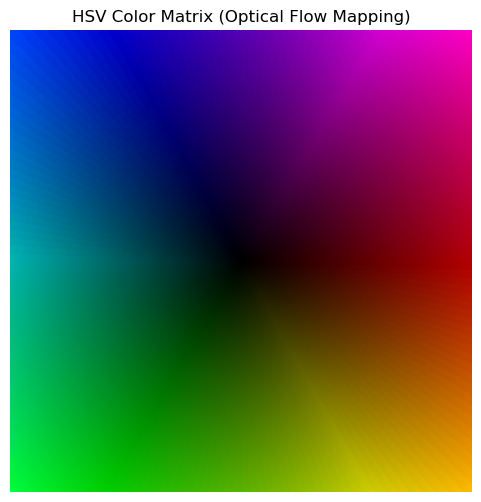

In [44]:
# Step 2: Capture video
cap = cv.VideoCapture(cv.samples.findFile("walking.mp4"))

# Step 2.1: showing the HSV colour matrix
color_matrix = generate_hsv_color_matrix(size=300)

plt.figure(figsize=(6, 6))
plt.imshow(color_matrix)
plt.title("HSV Color Matrix (Optical Flow Mapping)")
plt.xlabel("Direction (Hue)")
plt.ylabel("Speed (Brightness/Value)")
plt.axis('off')
plt.show()

 Prepare variables for processing the frames.

In [37]:
# Step 3: Read the first frame and initialize variables
ret, frame1 = cap.read()
prvs = cv.cvtColor(frame1, cv.COLOR_BGR2GRAY)
hsv = np.zeros_like(frame1)
hsv[..., 1] = 255

Steps 4, 5, and 6 

4. **Use the Farneback method** to compute the flow between frames.
5. **Visualize the results**: Convert the flow data to a visual format and display it.
6. **Handle key events**: Allow saving the frames and exiting the display.


#  Step 4: Processing Frames and Visualizing Dense Optical Flow

This step contains the main loop that processes the video frame-by-frame, calculates the **Dense Optical Flow** using the Farnebäck method, and visualizes the results using the standard HSV color coding. 


In [41]:
# Step 4: Process frames to calculate optical flow
while(1):
    ret, frame2 = cap.read()
    if not ret:
        cv.destroyAllWindows()
        print('No frames grabbed!')
        break

    next = cv.cvtColor(frame2, cv.COLOR_BGR2GRAY)
    flow = cv.calcOpticalFlowFarneback(prvs, next, None, 0.5, 3, 15, 3, 5, 1.2, 0)
    mag, ang = cv.cartToPolar(flow[..., 0], flow[..., 1])
    
    # Visualize the flow
    hsv[..., 0] = ang * 180 / np.pi / 2
    hsv[..., 2] = cv.normalize(mag, None, 0, 255, cv.NORM_MINMAX)
    bgr = cv.cvtColor(hsv, cv.COLOR_HSV2BGR)
    
    # Display the frame
    cv.imshow('frame2', bgr)
    # Step 5: Handle key events
    k = cv.waitKey(30) & 0xff
    if k == 27:  # Esc key
        break
    elif k == ord('s'):  # 's' key to save frames
        cv.imwrite('opticalfb.png', frame2)
        cv.imwrite('opticalhsv.png', bgr)

    prvs = next  # Update previous frame

# Cleanup
cv.destroyAllWindows()

No frames grabbed!



## The Farnebäck Algorithm Calculation

The core calculation is done by the **`cv.calcOpticalFlowFarneback`** function:

* `flow = cv.calcOpticalFlowFarneback(prvs, next, ...)`: This function calculates the flow vector $\mathbf{v} = (v_x, v_y)$ for **every single pixel** in the image, resulting in a **dense flow map** stored in the `flow` variable (a HxWx2 array).
* **Farnebäck Method:** This algorithm estimates motion by fitting a local **quadratic polynomial** to the pixel neighborhoods in the `prvs` (previous) and `next` (current) frames.

## Flow Visualization using HSV

The resulting flow is visualized using Hue, Saturation, Value (HSV) color space, mapping the vector properties to visual properties:

1.  **Vector Decomposition:** `mag, ang = cv.cartToPolar(flow[..., 0], flow[..., 1])` converts the flow vectors $(v_x, v_y)$ from Cartesian coordinates to their **magnitude** (`mag`) and **angle** (`ang`).
2.  **Color Mapping:**
    * **Hue (`hsv[..., 0]`):** Represents the **direction** of motion (angle). The entire $360^\circ$ circle of motion is mapped to the $0-180$ range of the Hue channel.
    * **Value (`hsv[..., 2]`):** Represents the **speed** or **magnitude** of motion. Faster motion results in a brighter pixel (higher Value). This channel is normalized to fit the $0-255$ range.
    * **Saturation (`hsv[..., 1]`):** Is set to a constant maximum value of 255 to ensure the colors are vivid.
3.  **Display:** The resulting HSV image is converted back to BGR (`bgr = cv.cvtColor(hsv, cv.COLOR_HSV2BGR)`) for display with `cv.imshow`.
4.  **Update:** `prvs = next` ensures that the current frame becomes the "previous" frame for the next iteration of the loop, maintaining continuous tracking.

## Task1
### Modify the Parameters

Change the parameters of the cv.calcOpticalFlowFarneback() function to see how it affects the optical flow visualization. Document your observations.

In [5]:
# Complete Task 1 here

## Task 2
### Experiment with Different Videos

Replace "vtest.avi" with another video file of your choice. Analyze the differences in optical flow between the videos. What do you notice about the motion in each video?

In [6]:
# Complete Task 2 here